In [1]:
# # 01. Розвідувальний аналіз даних (EDA)
# **Проєкт:** E-Commerce Customer Retention (`ecommerce_retention_lab1`)
# **Мета:** Дослідження розподілів, штучних/природних пропусків, аналіз захищених ознак (`CityTier`, `Gender`) та виявлення потенційних проксі-змінних.

# %%
import sys
from pathlib import Path

BASE_DIR = Path("..").resolve()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

from core.dataset_loader import (
    extract_features_and_target,
    get_prepared_dataset,
    read_data_config,
)

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
# ## 1. Завантаження датасету та первинний огляд

# %%
data_config = read_data_config("configs/dataset_config.yaml")
df = get_prepared_dataset(data_config, apply_injection=True)

print(f"Формат датасету: {df.shape[0]} рядків, {df.shape[1]} колонок")
df.info()

# %%
df.head()

Формат датасету: 5630 рядків, 20 колонок
<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             4786 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   s

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,NaN,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


Розподіл цільової змінної Churn (%):
Churn
0    83.161634
1    16.838366
Name: proportion, dtype: float64


C:\Users\Emin\AppData\Local\Temp\ipykernel_2832\2697897723.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="Churn", palette="Blues_d")


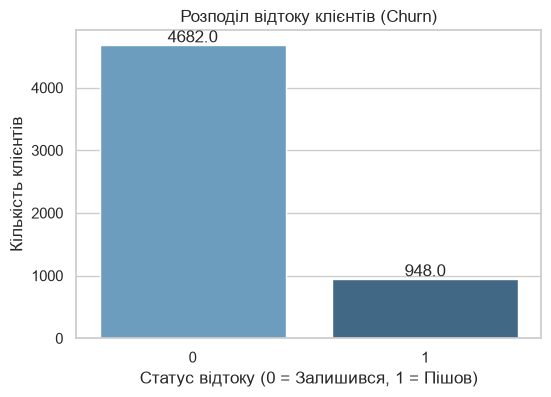

In [3]:
# ## 2. Аналіз цільової змінної (`Churn`)

# %%
churn_counts = df["Churn"].value_counts(normalize=True) * 100
print("Розподіл цільової змінної Churn (%):")
print(churn_counts)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Churn", palette="Blues_d")
plt.title("Розподіл відтоку клієнтів (Churn)")
plt.xlabel("Статус відтоку (0 = Залишився, 1 = Пішов)")
plt.ylabel("Кількість клієнтів")
for p in ax.patches:
    ax.annotate(
        f"{p.get_height()}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 5),
        textcoords="offset points",
    )
plt.show()

Загальний звіт по пропусках у датасеті:
                             missing_count  missing_share
CashbackAmount                        1126       0.200000
PreferedOrderCat                       844       0.149911
DaySinceLastOrder                      307       0.054529
OrderAmountHikeFromlastYear            265       0.047069
Tenure                                 264       0.046892
OrderCount                             258       0.045826
CouponUsed                             256       0.045471
HourSpendOnApp                         255       0.045293
WarehouseToHome                        251       0.044583


C:\Users\Emin\AppData\Local\Temp\ipykernel_2832\2647190225.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


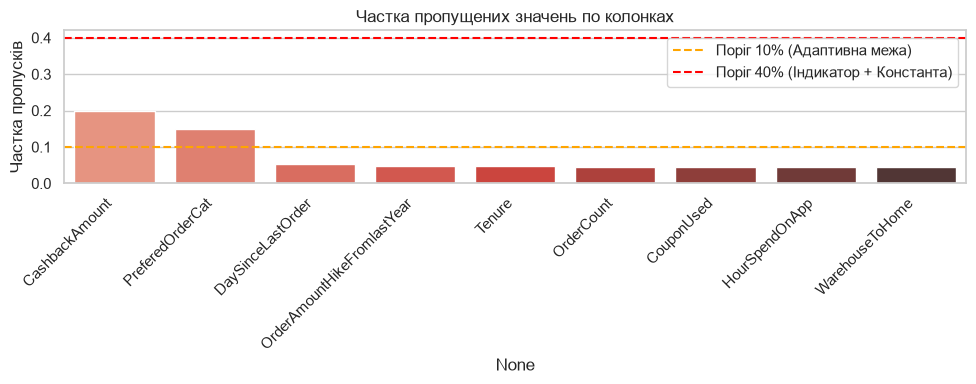

In [4]:
# ## 3. Профілювання пропусків (Природні + MCAR)

# %%
missing_summary = (
    df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_share=lambda x: x["missing_count"] / len(df))
    .query("missing_count > 0")
    .sort_values(by="missing_share", ascending=False)
)

print("Загальний звіт по пропусках у датасеті:")
print(missing_summary)

plt.figure(figsize=(10, 4))
sns.barplot(
    x=missing_summary.index, y=missing_summary["missing_share"], palette="Reds_d"
)
plt.xticks(rotation=45, ha="right")
plt.title("Частка пропущених значень по колонках")
plt.ylabel("Частка пропусків")
plt.axhline(0.10, color="orange", linestyle="--", label="Поріг 10% (Адаптивна межа)")
plt.axhline(0.40, color="red", linestyle="--", label="Поріг 40% (Індикатор + Константа)")
plt.legend()
plt.tight_layout()
plt.show()

   CityTier  count  churn_rate_%
0         1   3666     14.511729
1         2    242     19.834711
2         3   1722     21.370499


C:\Users\Emin\AppData\Local\Temp\ipykernel_2832\1143687711.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  city_churn.rename(columns={"mean": "churn_rate_%"}, inplace=True)
C:\Users\Emin\AppData\Local\Temp\ipykernel_2832\1143687711.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_churn, x="CityTier", y="churn_rate_%", palette="viridis")


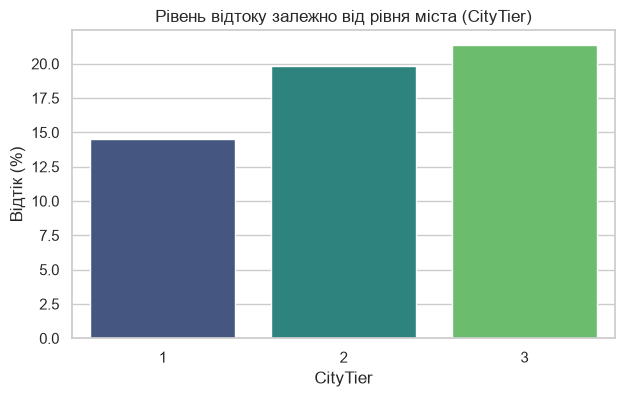

In [5]:
# ## 4. Етичний аналіз: Захищені ознаки (`CityTier`, `Gender`) та Проксі

# %% [markdown]
# ### 4.1. Основна захищена ознака — `CityTier`

# %%
city_churn = df.groupby("CityTier")["Churn"].agg(["count", "mean"]).reset_index()
city_churn["mean"] = city_churn["mean"] * 100
city_churn.rename(columns={"mean": "churn_rate_%"}, inplace=True)
print(city_churn)

plt.figure(figsize=(7, 4))
sns.barplot(data=city_churn, x="CityTier", y="churn_rate_%", palette="viridis")
plt.title("Рівень відтоку залежно від рівня міста (CityTier)")
plt.ylabel("Відтік (%)")
plt.show()

In [6]:
# ### 4.2. Аналіз потенційного проксі `PreferredPaymentMode` для `CityTier`

# %%
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))


v_payment = cramers_v(df["CityTier"], df["PreferredPaymentMode"])
v_device = cramers_v(df["CityTier"], df["PreferredLoginDevice"])
v_gender = cramers_v(df["CityTier"], df["Gender"])

print(f"Cramér's V між CityTier та PreferredPaymentMode: {v_payment:.4f}")
print(f"Cramér's V між CityTier та PreferredLoginDevice:  {v_device:.4f}")
print(f"Cramér's V між CityTier та Gender:                {v_gender:.4f}")

Cramér's V між CityTier та PreferredPaymentMode: 0.4377
Cramér's V між CityTier та PreferredLoginDevice:  0.1049
Cramér's V між CityTier та Gender:                0.0456


In [7]:
# ## 5. Синоніми категорій та нормалізація назв

# %%
print("Особливості PreferredLoginDevice:", df["PreferredLoginDevice"].unique())
print("Особливості PreferredPaymentMode:", df["PreferredPaymentMode"].unique())

# %% [markdown]
# ## 6. Збереження ключових висновків EDA
# * `CityTier` (Tier 3) має суттєво вищий відтік (~21.4%), ніж Tier 1 (~14.5%), що підтверджує критичність етичного виключення цієї ознаки з моделі.
# * `PreferredPaymentMode` демонструє сильний проксі-зв'язок (Cramér's V = 0.44) з `CityTier` (зокрема використання `E wallet`).

Особливості PreferredLoginDevice: <StringArray>
['Mobile Phone', 'Phone', 'Computer']
Length: 3, dtype: str
Особливості PreferredPaymentMode: <StringArray>
['Debit Card', 'UPI', 'CC', 'Cash on Delivery', 'E wallet', 'COD',
 'Credit Card']
Length: 7, dtype: str
